Enter CSV dataset path:  /kaggle/input/datasets/uciml/iris/Iris.csv



Dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Columns in dataset:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']



Enter target/output column:  Species



Choose an algorithm:
1. SVM
2. Decision Tree
3. Logistic Regression
4. Linear Regression


Enter your choice (1-4):  2



Decision Tree selected
Accuracy: 1.0


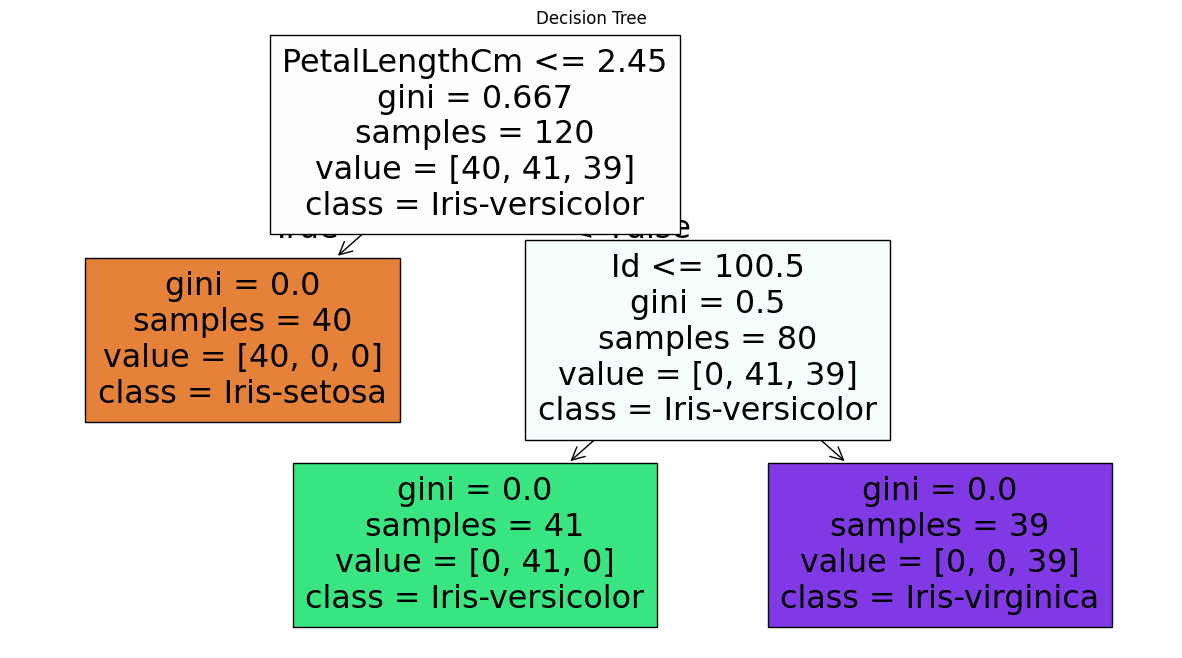

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

# Take dataset from user
path = input("Enter CSV dataset path: ")
data = pd.read_csv(path)

print("\nDataset:")
print(data.head())

print("\nColumns in dataset:")
print(list(data.columns))

# Select target column
target = input("\nEnter target/output column: ")

X = data.drop(target, axis=1)
y = data[target]

# Convert categorical columns into numbers
X = pd.get_dummies(X)
X = X.fillna(0)

print("\nChoose an algorithm:")
print("1. SVM")
print("2. Decision Tree")
print("3. Logistic Regression")
print("4. Linear Regression")

choice = int(input("Enter your choice (1-4): "))

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------------- SVM ----------------
if choice == 1:

    print("\nSVM selected")

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = SVC()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))

    # Graph
    plt.figure(figsize=(8, 5))
    plt.plot(range(len(y_test)), y_test.values, 'o-', label="Actual")
    plt.plot(range(len(y_test)), y_pred, 'x-', label="Predicted")

    plt.title("SVM - Actual vs Predicted")
    plt.xlabel("Test Sample")
    plt.ylabel("Class")
    plt.legend()
    plt.grid()
    plt.show()


# ---------------- Decision Tree ----------------
elif choice == 2:

    print("\nDecision Tree selected")

    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))

    # Decision Tree Graph
    plt.figure(figsize=(15, 8))

    plot_tree(
        model,
        feature_names=X.columns,
        class_names=[str(x) for x in model.classes_],
        filled=True
    )

    plt.title("Decision Tree")
    plt.show()


# ---------------- Logistic Regression ----------------
elif choice == 3:

    print("\nLogistic Regression selected")

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))

    # Graph
    plt.figure(figsize=(8, 5))

    plt.plot(
        range(len(y_test)),
        y_test.values,
        'o-',
        label="Actual"
    )

    plt.plot(
        range(len(y_test)),
        y_pred,
        'x-',
        label="Predicted"
    )

    plt.title("Logistic Regression - Actual vs Predicted")
    plt.xlabel("Test Sample")
    plt.ylabel("Class")
    plt.legend()
    plt.grid()
    plt.show()


# ---------------- Linear Regression ----------------
elif choice == 4:

    print("\nLinear Regression selected")

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
    print("R2 Score:", r2_score(y_test, y_pred))

    # Graph
    plt.figure(figsize=(8, 5))

    plt.scatter(
        y_test,
        y_pred,
        label="Predictions"
    )

    plt.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        label="Regression Line"
    )

    plt.title("Linear Regression")
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.legend()
    plt.grid()
    plt.show()


else:
    print("Invalid choice!")